# When SciPy says "converged" but it isn't a root
### CSCI 3656 Group Project: Improving SciPy root-finding reliability

**Motivation:** [SciPy issue #6379](https://github.com/scipy/scipy/issues/6379). `scipy.optimize.newton`
can return `converged=True` at a point that is not a root. The cause is its stopping rule: it stops when
the **step** $|x_{k+1}-x_k|$ is small, and it never checks the **residual** $|f(x_k)|$. The SciPy docs
acknowledge this: the step-size criterion can be satisfied away from a root.

This notebook:
1. Reproduces the issue
2. Explains *why* the secant method stops there
3. Shows our tool, `reliable_root`, which verifies the answer and falls back to Brent's method
4. Shows benchmark results across 8 equations and 101 initial guesses
5. Is a short tutorial on using the tool, including its limitations

## 1. Reproduce the issue

In [1]:
import numpy as np
import scipy
from scipy.optimize import newton

def f(x):
    return x**4 - x**2 + 1

root, info = newton(f, 0.001, full_output=True, disp=False)
print("SciPy version :", scipy.__version__)
print("Returned root :", root)
print("f(root)       :", f(root))
print("Converged     :", info.converged)

SciPy version : 1.18.1
Returned root : 0.0009999814755135925
f(root)       : 0.9999990000380485
Converged     : True


SciPy reports success, but $f(x)\approx 1$. In fact $f(x) = x^4 - x^2 + 1 = (x^2-\tfrac12)^2 + \tfrac34 \ge \tfrac34$,
so **this function has no real root at all**. The correct answer is "no root found", not a number.

## 2. Why does the secant method stop there?

In [2]:
iterates = []
def f_logged(x):
    iterates.append(x)
    return f(x)

x_final = newton(f_logged, 0.001, disp=False)
iterates.append(x_final)  # returned without being evaluated by SciPy
print(f"{'k':>2} {'x_k':>22} {'f(x_k)':>16} {'|step|':>12}")
for k, x in enumerate(iterates):
    step = abs(x - iterates[k-1]) if k else float('nan')
    print(f"{k:>2} {x:22.15g} {f(x):16.6g} {step:12.3g}")
print("\nLast row = the value SciPy returns. Its step is below SciPy's default tol = 1.48e-8, so it stops.")

 k                    x_k           f(x_k)       |step|
 0                  0.001         0.999999          nan
 1              0.0011001         0.999999       0.0001
 2       476.169378018004      5.14096e+10          476
 3   0.000999990737756796         0.999999          476
 4   0.000999981475513593         0.999999     9.26e-09

Last row = the value SciPy returns. Its step is below SciPy's default tol = 1.48e-8, so it stops.


Without a derivative, `newton` runs the **secant method**:
$x_{k+1} = x_k - f(x_k)\,\dfrac{x_k - x_{k-1}}{f(x_k)-f(x_{k-1})}$.

Near $x=0$ the function is almost flat ($f'(0)=0$), so the first secant step jumps to $x\approx 476$, where $f\approx 5\times10^{10}$.
The secant line from that point back to $x\approx 0.001$ is extremely steep, so the next step has size
$\approx 1/10^{8} \approx 10^{-8}$. That is **below the tolerance**, so SciPy stops.

A small step means the *secant slope was large*, not that we are near a root. Conditioning matters here:
the step size measures distance to a root only when the local linear model is accurate.

## 3. Our tool: `reliable_root`

`improved_root.reliable_root(f, x0, ...)` calls SciPy's `newton` exactly as a user would, then:

| Stage | What it does |
|---|---|
| **Verify** | Residual test $\lvert f(x)\rvert \le$ `ftol` **and** Newton-step test $\lvert f(x)/f'(x)\rvert \le$ `xtol`$\cdot\max(1,\lvert x\rvert)$ (an estimate of the distance to a simple root; $f'$ by central difference if not given). Exact zeros are rejected if $f$ is also exactly zero on both sides (underflow). |
| **Bracket** | Use the user's bracket $[a,b]$ if $f(a)f(b)<0$, otherwise search outward from $x_0$ for a sign change. |
| **Recover** | Run Brent's method (`brentq`), which is guaranteed to converge on a valid bracket, and verify *its* answer too. |
| **Report** | Return a `RootReport` with a status: `reliable`, `recovered`, `no_root_found`, or `unreliable`. |

It never invents a root. If nothing verifies, `root` is `None`.

In [3]:
from improved_root import reliable_root

report = reliable_root(f, 0.001)
print(report)

Status          : NO_ROOT_FOUND
Root            : None
Method          : none
|f(root)|       : 1.000e+00
|f/f'| estimate : 5.000e+02
SciPy returned  : 0.0009999814755135925 (converged=True, |f|=1.000e+00)
Function evals  : 108 total (4 by SciPy)
Message         : No verified root: SciPy's answer failed verification and no sign-change bracket was found. The function may have no real root near x0.


The tool flags SciPy's false convergence and correctly reports that **no root was found**.

### Recovery: Newton cycles on $x^3 - 2x + 2$

In [4]:
g  = lambda x: x**3 - 2*x + 2
dg = lambda x: 3*x**2 - 2

r, info = newton(g, 0.0, fprime=dg, full_output=True, disp=False)
print("SciPy:", r, "converged =", info.converged, " (iterates cycle 0 -> 1 -> 0 -> ...)\n")
print(reliable_root(g, 0.0, fprime=dg))

SciPy: 0.0 converged = False  (iterates cycle 0 -> 1 -> 0 -> ...)

Status          : RECOVERED
Root            : -1.7692923542386314
Method          : scipy.brentq
|f(root)|       : 0.000e+00
|f/f'| estimate : 0.000e+00
SciPy returned  : 0.0 (converged=False, |f|=2.000e+00)
Function evals  : 87 total (50 by SciPy)
Message         : Recovered a verified root with Brent's method.


### Recovery with a user-supplied bracket: $\arctan(x)$ from $x_0 = 3$ (Newton diverges)

In [5]:
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
r, info = newton(np.arctan, 3.0, fprime=lambda x: 1/(1+x**2), full_output=True, disp=False)
print("SciPy:", r, "converged =", info.converged, "\n")
print(reliable_root(np.arctan, 3.0, fprime=lambda x: 1/(1+x**2), bracket=(-1, 2)))

SciPy: -3.7947679049613913e+292 converged = False 

Status          : RECOVERED
Root            : -8.97408165779423e-27
Method          : scipy.brentq
|f(root)|       : 8.974e-27
|f/f'| estimate : 8.974e-27
SciPy returned  : -3.7947679049613913e+292 (converged=False, |f|=1.571e+00)
Function evals  : 23 total (10 by SciPy)
Message         : Recovered a verified root with Brent's method.


### A second false convergence: underflow
For $f(x) = x e^{-x}$ from $x_0 = 1$, $f'(1)=0$, so the secant step overshoots to $x\approx 10^4$.
There $e^{-x}$ **underflows to exactly 0.0**, so $f(x)=0$ in floating point and SciPy declares success.
Note that a residual test alone **would not catch this**: the residual really is zero.

In [6]:
h = lambda x: x * np.exp(-x)
r, info = newton(h, 1.0, full_output=True, disp=False)
print("SciPy:", r, "f(r) =", h(r), "converged =", info.converged, "\n")
print(reliable_root(h, 1.0))

SciPy: 10002.333394351925 f(r) = 0.0 converged = True 

Status          : RECOVERED
Root            : -1.1040518576238775e-24
Method          : scipy.brentq
|f(root)|       : 1.104e-24
|f/f'| estimate : 1.104e-24
SciPy returned  : 10002.333394351925 (converged=True, |f|=0.000e+00)
Function evals  : 41 total (3 by SciPy)
Message         : Recovered a verified root with Brent's method.


## 4. Benchmark results

`benchmark.py` runs both solvers on **8 equations x 101 initial guesses in $[-5, 5]$ x 2 modes** (secant, and Newton with $f'$),
for 1616 runs in all, and checks every answer against the known true roots.

In [7]:
import benchmark
rows = benchmark.run_benchmark()
summary = benchmark.summarize(rows)
benchmark.print_table(summary)

mode    problem                  SciPy valid SciPy FALSE ours valid ours FALSE nfev SciPy nfev ours
---------------------------------------------------------------------------------------------------
secant  x^2 - 2                       100.0%        0.0%     100.0%       0.0%        8.4      11.4
secant  cos(x) - x                    100.0%        0.0%     100.0%       0.0%        8.8      11.4
secant  (x - 1)^2                     100.0%        0.0%     100.0%       0.0%       38.7      41.7
secant  x^3 - 2x + 2                   91.1%        0.0%     100.0%       0.0%       22.1      28.2
secant  arctan(x)                      46.5%        0.0%     100.0%       0.0%       10.7      31.6
secant  x exp(-x)                      58.4%        1.0%     100.0%       0.0%       28.4      46.4
secant  cbrt(x)                         1.0%        0.0%       1.0%       0.0%       51.5     118.0
secant  x^4 - x^2 + 1  (#6379)          0.0%        5.0%       0.0%       0.0%       50.0     154.0


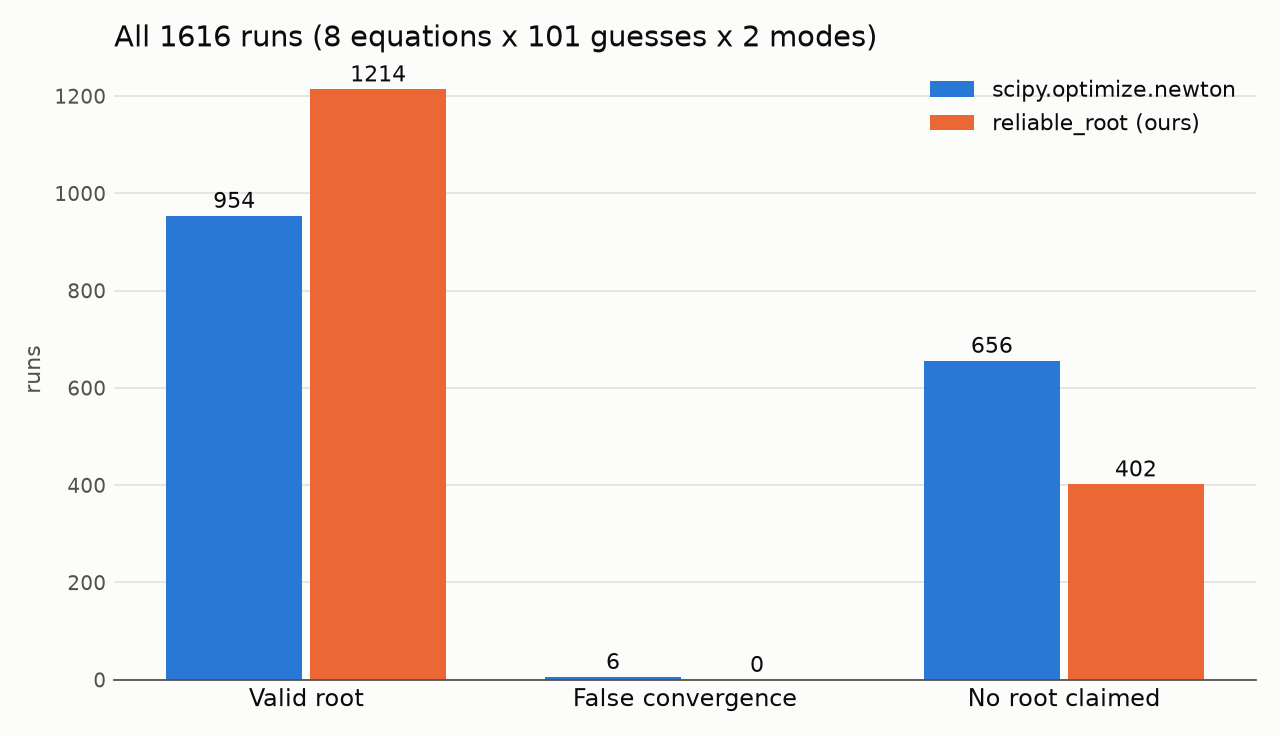

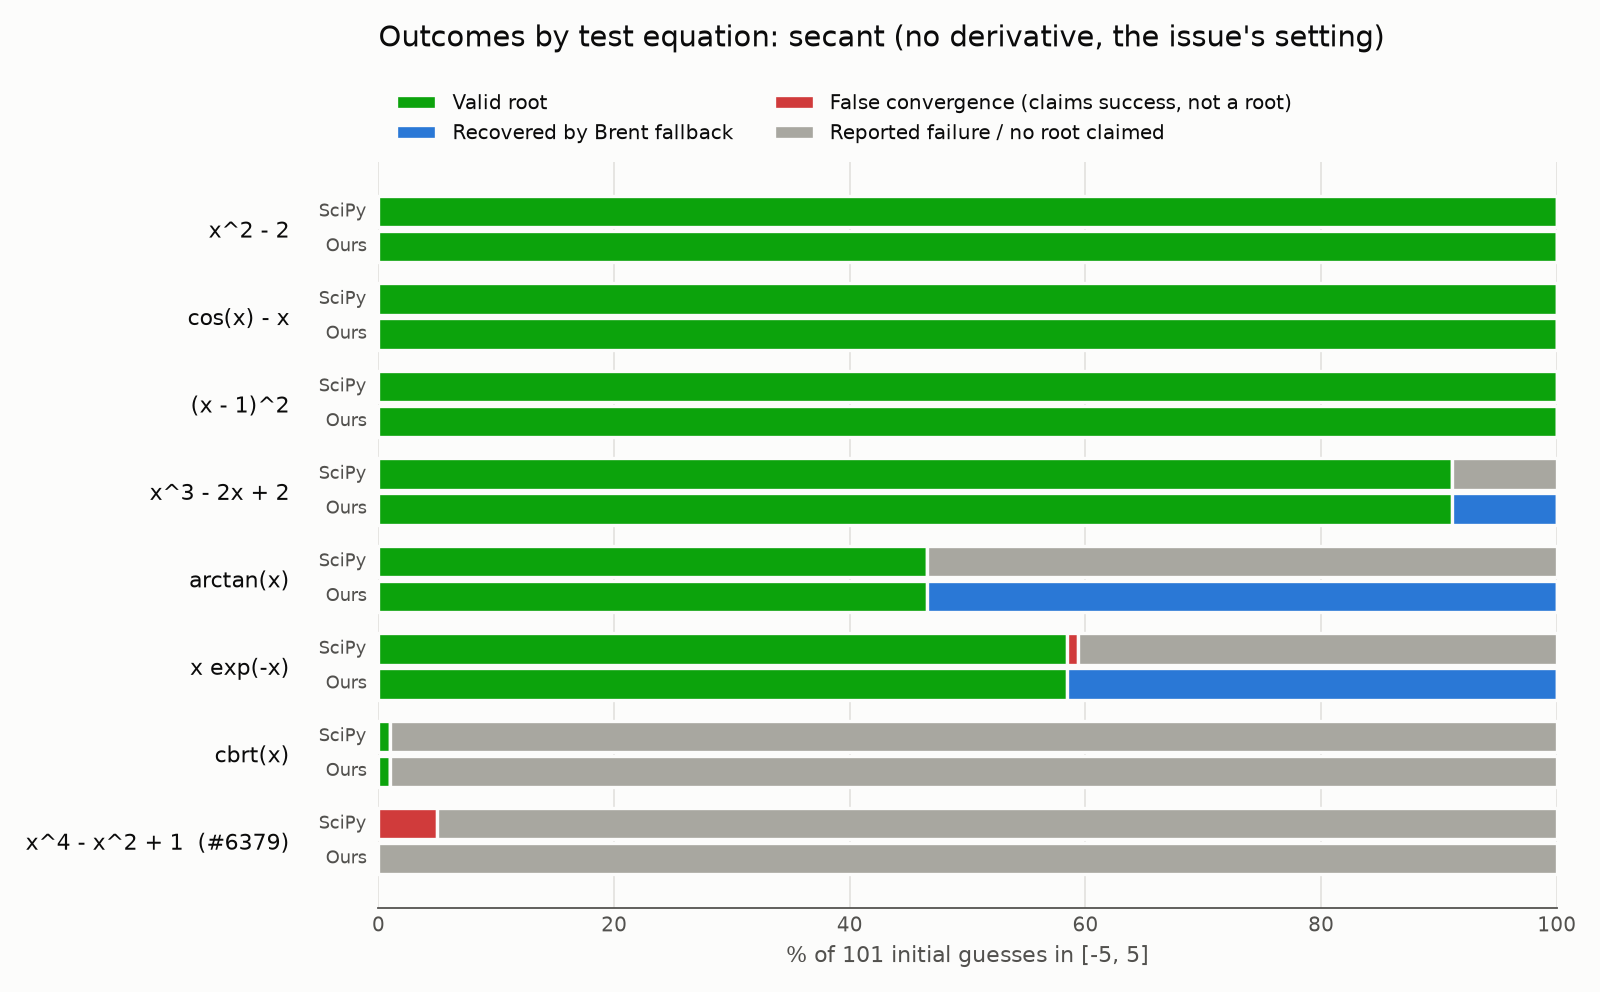

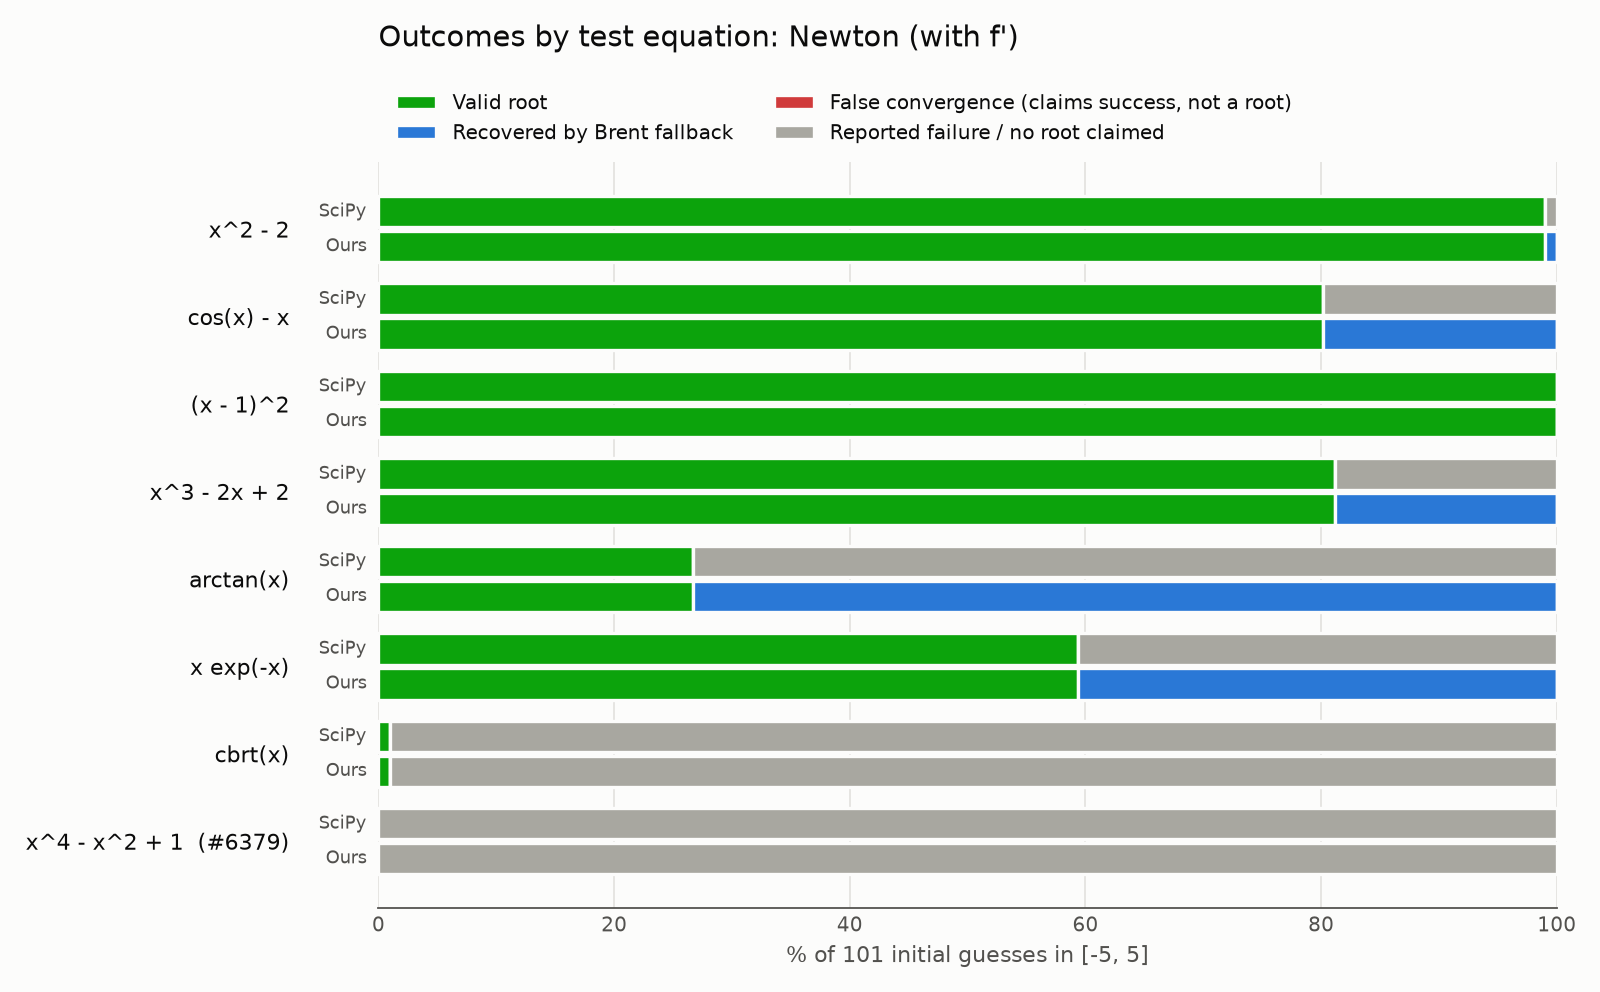

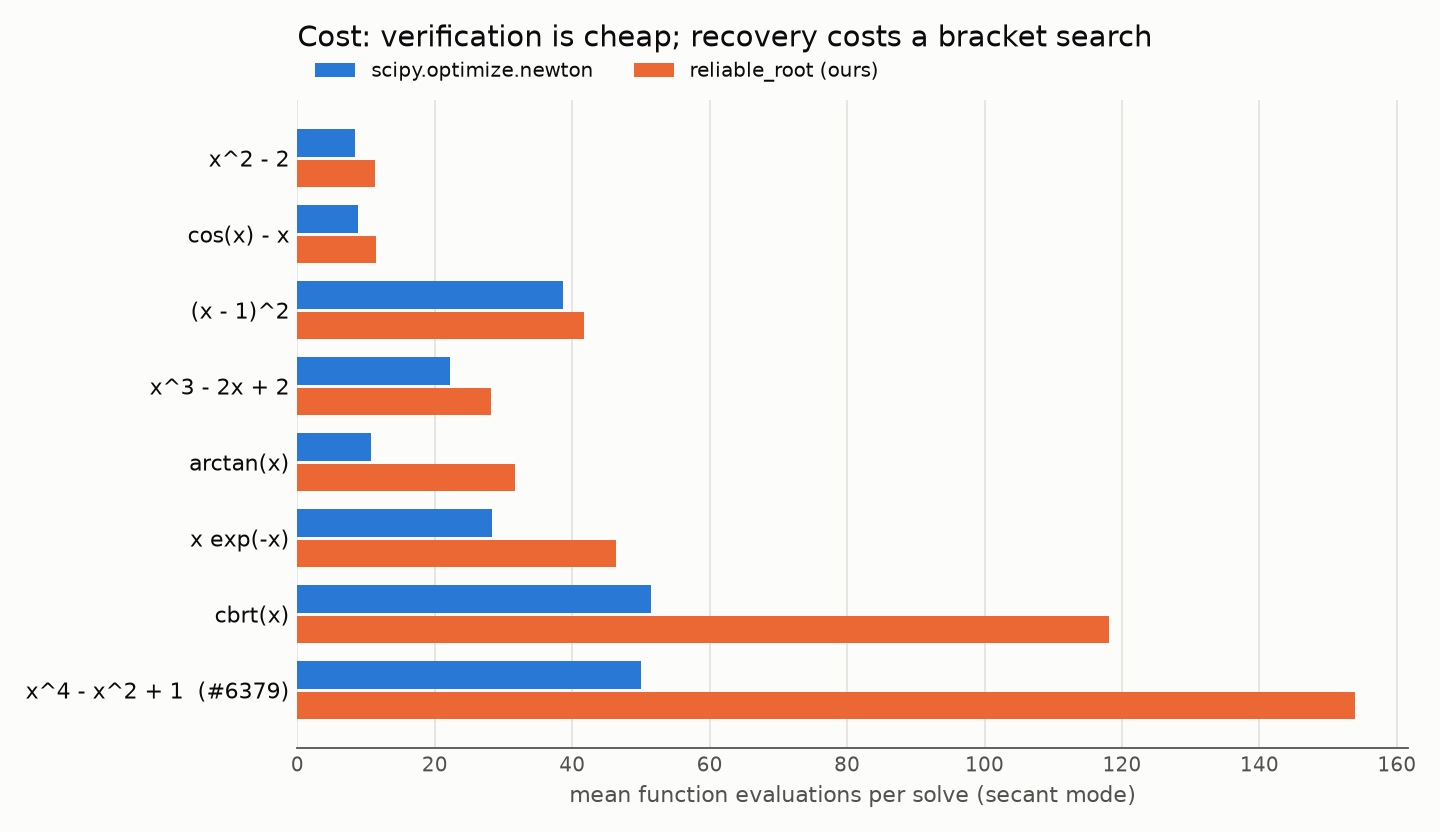

In [8]:
from IPython.display import Image, display
for name in ["totals", "outcomes_secant", "outcomes_newton", "cost_nfev"]:
    display(Image(filename=f"figures/{name}.png", width=760))

**Takeaways**
- **False convergence: 6 → 0.** SciPy claimed success at a non-root 6 times (5 in the #6379 equation, 1 from underflow). Our tool made **zero** false claims.
- **Valid roots: 954 → 1214** out of 1616 runs. The Brent fallback recovered roots where Newton/secant cycled (`x^3-2x+2`), diverged (`arctan`), or ran down a flat tail (`x e^{-x}`).
- **Cost:** when SciPy's answer is already good, verification costs only **~2-3 extra evaluations**. Recovery costs a bracket search, and proving that *no* root exists is the most expensive case (~150 evaluations).

## 5. Limitations (what the tool cannot do)

In [9]:
print("Pole (1/x): sign change, but not a root")
print(reliable_root(lambda x: 1/x, 0.5).message, "\n")

print("Steep root (cbrt): residual is ill-conditioned")
print(reliable_root(np.cbrt, 1.0).message, "\n")

print("Same cbrt problem with a looser residual tolerance")
print(reliable_root(np.cbrt, 1.0, ftol=1e-4).status)

Pole (1/x): sign change, but not a root
Brent's method converged to x=-7.26672e-15, but |f| = 1.38e+14 > ftol. |f| grows toward this point, so the sign change is probably a pole or discontinuity, not a root. 

Steep root (cbrt): residual is ill-conditioned
Brent's method converged to x=-9.89962e-16, but |f| = 9.97e-06 > ftol. |f| shrinks toward this point, so it is probably a root where f is very steep (ill-conditioned residual, e.g. cbrt(x)); loosen ftol if that is acceptable for your problem. 

Same cbrt problem with a looser residual tolerance
recovered


- **`ftol` is problem-dependent.** $10^{-6}$ is a demonstration default. For $\sqrt[3]{x}$, even $x = 10^{-15}$ gives $|f| = 10^{-5}$, so no floating-point $x$ near the root passes `ftol = 1e-6`. Scale `ftol` to your function.
- **Even-multiplicity roots** (e.g. $(x-1)^2$) have no sign change, so the bracket search can't find them. They are only found if Newton/secant reaches them itself.
- **Poles** create sign changes. Brent converges to them, and verification correctly rejects them.
- The bracket search samples a finite range around $x_0$, so it can miss distant roots. Supply `bracket=(a, b)` when you know one.

## 6. Tutorial: using the tool

```python
from improved_root import reliable_root

rep = reliable_root(f, x0)                         # secant (like newton without fprime)
rep = reliable_root(f, x0, fprime=df)              # Newton
rep = reliable_root(f, x0, bracket=(a, b))         # guaranteed fallback if f(a)*f(b) < 0
rep = reliable_root(f, x0, ftol=1e-10, xtol=1e-10) # stricter verification

if rep.reliable:
    use(rep.root)
else:
    print(rep.message)   # explains what went wrong
```

Run `python original_problem.py`, `python improved_root.py`, and `python benchmark.py` to reproduce everything here.